In [1]:
"""
Unit 5: Evolving Your IPD Agent with Genetic Algorithms
========================================================

In Unit 4, you hand-coded agent strategies like Tit-for-Tat.
In Unit 5, you'll use evolution to DISCOVER strategies automatically.

By the end, you'll have an evolved agent saved as a JSON file for the tournament!
"""

# ============================================================================
# SETUP: Import everything from previous units
# ============================================================================

import random
import numpy as np
import json
import matplotlib.pyplot as plt
from agents import Agent, INVEST, UNDERCUT
from game_engine import Game, Tournament

# Import all hand-coded agents from Unit 4
from agents import (
    AlwaysInvestAgent, AlwaysUndercutAgent, TitForTatAgent,
    GrimTriggerAgent, PavlovAgent, TitForTwoTatsAgent,
    GenerousTitForTatAgent, AdaptiveAgent, RandomAgent,
    SuspiciousTitForTatAgent, GradualAgent, HardMajorityAgent,
    SoftMajorityAgent, ProberAgent
)

print("✅ Imports complete!")

✅ Imports complete!


In [2]:

# ============================================================================
# PART 1: THE EVOLVABLE AGENT (PROVIDED - Read but don't modify)
# ============================================================================

class EvolvableAgent(Agent):
    """
    An agent whose strategy is controlled by 6 genes (numbers from 0 to 1).
    
    Think of genes as "strategy dials" you can tune:
    
    Gene[0] - Initial Cooperation (0=hostile start, 1=friendly start)
    Gene[1] - Cooperation Response (if opponent cooperates, how likely to cooperate back?)
    Gene[2] - Defection Response (if opponent defects, how likely to defect back?)
    Gene[3] - Forgiveness (after retaliation, chance to forgive)
    Gene[4] - Memory Length (0=last 1 round, 1=last 10 rounds)
    Gene[5] - Retaliation Threshold (what % of defections triggers retaliation)
    """
    
    def __init__(self, genes=None, name="Evolved Agent"):
        if genes is None:
            # Create random genes if none provided
            genes = [random.random() for _ in range(6)]
        
        self.genes = genes
        super().__init__(name, f"Genes: [{', '.join([f'{g:.2f}' for g in genes])}]")
    
    def choose_action(self) -> bool:
        """Decision logic based on genes - SIMPLIFIED FOR LEARNING"""
        
        # First 3 rounds: use initial cooperation gene
        if self.round_num < 3:
            return random.random() < self.genes[0]
        
        # Calculate memory window (gene[4])
        memory_length = max(1, int(self.genes[4] * 10) + 1)
        recent_history = self.history[-memory_length:]
        
        # Calculate opponent's recent COOPERATION rate (not defection!)
        cooperation_rate = sum(recent_history) / len(recent_history)
        
        # If opponent is mostly cooperating, reciprocate
        if cooperation_rate >= 0.5:
            return random.random() < self.genes[1]  # gene[1] = cooperate response
        
        # If opponent is mostly defecting, retaliate or forgive
        else:
            # Retaliate with probability gene[2]
            if random.random() < self.genes[2]:
                return UNDERCUT
            # Or forgive with probability gene[3]
            elif random.random() < self.genes[3]:
                return INVEST
            else:
                return UNDERCUT


In [3]:

# ============================================================================
# PART 2: DEFINE THE OPPONENT ECOSYSTEM
# ============================================================================

# ============================================================================
# EXPANDED OPPONENT POOL
# ============================================================================

# Full pool of all possible opponents
full_opponent_pool = [
    # Cooperative agents
    AlwaysInvestAgent(),
    TitForTatAgent(),
    GrimTriggerAgent(),
    PavlovAgent(),
    TitForTwoTatsAgent(),
    GenerousTitForTatAgent(),
    AdaptiveAgent(),
    
    # Aggressive agents
    AlwaysUndercutAgent(),
    SuspiciousTitForTatAgent(),
    
    # Sophisticated agents
    GradualAgent(),
    ProberAgent(),
    
    # Majority-based agents
    HardMajorityAgent(),
    SoftMajorityAgent(),
    
    # Random agents with different cooperation levels
    RandomAgent(0.9),
    RandomAgent(0.7),
    RandomAgent(0.5),
    RandomAgent(0.3),
    RandomAgent(0.1),
]

print(f"\n📚 Full opponent library: {len(full_opponent_pool)} agents available")

# For initial evolution, randomly sample opponents
opponent_pool = random.sample(full_opponent_pool, 10)

print(f"🎲 Randomly selected {len(opponent_pool)} opponents for this evolution:")
for i, opp in enumerate(opponent_pool, 1):
    print(f"  {i:2d}. {opp.name:25s} - {opp.description}")
print("="*70)




📚 Full opponent library: 18 agents available
🎲 Randomly selected 10 opponents for this evolution:
   1. Gradual                   - Escalates punishment after each betrayal
   2. Generous Tit-for-Tat      - Tit-for-Tat with 10% forgiveness
   3. Hard Majority             - Defects if opponent defects >50% of time
   4. Grim Trigger              - Invests until betrayed once, then undercuts forever
   5. Pavlov                    - Win-Stay-Lose-Shift strategy
   6. Suspicious Tit-for-Tat    - Starts hostile, then copies opponent
   7. Always Undercut           - Always undercuts competitors
   8. Random (0.7)              - Randomly invests 70% of the time
   9. Random (0.9)              - Randomly invests 90% of the time
  10. Random (0.1)              - Randomly invests 10% of the time


In [6]:

# ============================================================================
# PART 3: GENETIC ALGORITHM FUNCTIONS (YOUR TODO!)
# ============================================================================

def initialize_population(pop_size):
    """
    Create initial population of random agents.
    
    Args:
        pop_size: Number of agents in population
    
    Returns:
        List of EvolvableAgent objects with random genes
    """
    population = []
    for i in range(pop_size):
        agent = EvolvableAgent(name=f"Agent_{i}")
        population.append(agent)
    return population


def evaluate_fitness(agent, opponents, num_rounds=50):
    """
    Measure how good an agent is by playing against all opponents.
    
    Args:
        agent: The EvolvableAgent to evaluate
        opponents: List of opponent agents to play against
        num_rounds: Number of rounds per game
    
    Returns:
        Float: Average score per game (higher is better)
    """
    total_score = 0
    num_games = 0
    
    for opponent in opponents:
        game = Game(agent, opponent, num_rounds=num_rounds)
        score, _ = game.play()
        total_score += score
        num_games += 1
    
    avg_score = total_score / num_games
    return avg_score



def tournament_selection(population, fitnesses, tournament_size=3):
    selected = []

    for _ in range(len(population)):
        contestants_idx = random.sample(
            range(len(population)), tournament_size
        )

        best_idx = max(
            contestants_idx, key=lambda i: fitnesses[i]
        )

        winner_genes = population[best_idx].genes.copy()
        selected.append(EvolvableAgent(genes=winner_genes))

    return selected
    
    
    selected = []
    for _ in range(len(population)):
        random_agent = random.choice(population)
        selected.append(EvolvableAgent(genes=random_agent.genes.copy()))
    
    return selected
    """
    Select parents using tournament selection.
    
    Tournament selection:
    1. Pick tournament_size random individuals
    2. Choose the one with best fitness
    3. Repeat until we have pop_size selected parents
    
    Args:
        population: List of agents
        fitnesses: List of fitness scores (parallel to population)
        tournament_size: How many agents compete in each tournament
    
    Returns:
        List of selected agents (same length as population)
    """
    selected = []
    
    for _ in range(len(population)):
        # Pick random contestants
        contestants_idx = random.sample(range(len(population)), tournament_size)
        
        # Find the one with best fitness
        best_idx = max(contestants_idx, key=lambda i: fitnesses[i])
        
        # Add winner to selected (make a copy of genes)
        winner_genes = population[best_idx].genes.copy()
        selected.append(EvolvableAgent(genes=winner_genes))
    
    return selected


def crossover_and_mutate(parent1, parent2, mutation_rate=0.15):
    
    crossover_point = random.randint(1, 5)

    child_genes = (
        parent1.genes[:crossover_point]
        + parent2.genes[crossover_point:]
    )

    for i in range(len(child_genes)):
        if random.random() < mutation_rate:
            child_genes[i] += random.gauss(0, 0.2)
            child_genes[i] = max(0.0, min(1.0, child_genes[i]))

    return EvolvableAgent(genes=child_genes)

    
    child_genes = [random.random() for _ in range(6)]
    
    return EvolvableAgent(genes=child_genes)

    """
    Create a child from two parents using crossover and mutation.
    
    Crossover (single-point):
    1. Pick a random split point (1 to 5)
    2. Take genes before split from parent1
    3. Take genes after split from parent2
    
    Mutation:
    1. For each gene, with probability=mutation_rate:
    2. Add Gaussian noise (mean=0, std=0.2)
    3. Clip gene to stay in range [0, 1]
    
    Args:
        parent1: First parent EvolvableAgent
        parent2: Second parent EvolvableAgent
        mutation_rate: Probability of mutating each gene
    
    Returns:
        New EvolvableAgent (the child)
    """
    # Crossover
    crossover_point = random.randint(1, 5)  # Random split between 1 and 5
    child_genes = (parent1.genes[:crossover_point] + 
                   parent2.genes[crossover_point:])
    
    # Mutation
    for i in range(len(child_genes)):
        if random.random() < mutation_rate:
            # Add random noise
            child_genes[i] += random.gauss(0, 0.2)
            # Keep gene in valid range [0, 1]
            child_genes[i] = max(0.0, min(1.0, child_genes[i]))
    
    return EvolvableAgent(genes=child_genes)


def evolve(generations=25, pop_size=20, opponents=None, mutation_rate=0.15, elitism=2):
    """
    Run the genetic algorithm to evolve an agent.
    
    Process:
    1. Create initial random population
    2. For each generation:
       a. Evaluate fitness of all agents
       b. Select parents via tournament selection
       c. Create children via crossover & mutation
       d. Keep best agents (elitism)
    3. Return the best agent found
    
    Args:
        generations: Number of generations to evolve
        pop_size: Size of population
        opponents: List of opponents to evaluate against
        mutation_rate: Probability of gene mutation
        elitism: Number of best agents to keep unchanged
    
    Returns:
        Best EvolvableAgent found
    """
    if opponents is None:
        opponents = opponent_pool
    
    print(f"\n🧬 EVOLUTION STARTING")
    print(f"{'='*70}")
    print(f"Population: {pop_size} | Generations: {generations} | Mutation: {mutation_rate}")
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print(f"{'='*70}\n")
    
    best_fitness_history = []
    avg_fitness_history = []
    
    population = initialize_population(pop_size)
    
    best_overall_agent = None
    best_overall_fitness = -float('inf')
    
    for gen in range(generations):
        
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(agent, opponents, num_rounds=50)
            fitnesses.append(fitness)
        
        # Track statistics
        best_fitness = max(fitnesses)
        avg_fitness = sum(fitnesses) / len(fitnesses)
        best_fitness_history.append(best_fitness)
        avg_fitness_history.append(avg_fitness)
        
        
        best_idx = fitnesses.index(best_fitness)
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            best_overall_agent = EvolvableAgent(
                genes=population[best_idx].genes.copy()
            )
        
        # Print progress
        print(f"Gen {gen+1:3d}/{generations}: "
              f"Best={best_fitness:6.2f} | Avg={avg_fitness:6.2f} | "
              f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}")
        
        # Create next generation
        if gen < generations - 1:
        
            # Sort agents by fitness, highest first
            sorted_indices = sorted(
                range(len(fitnesses)),
                key=lambda i: fitnesses[i],
                reverse=True
            )

            # Keep the best agents the same
            next_population = []
            for i in range(min(elitism, pop_size)):
                elite_genes = population[sorted_indices[i]].genes.copy()
                next_population.append(EvolvableAgent(genes=elite_genes))

            # Select parents
            selected = tournament_selection(population, fitnesses)

            # Create children using crossover and mutation
            while len(next_population) < pop_size:
                parent1, parent2 = random.sample(selected, 2)
                child = crossover_and_mutate(
                    parent1, parent2, mutation_rate
                )
                next_population.append(child)

            population = next_population
    
    print(f"\n{'='*70}")
    print(f"✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best fitness achieved: {best_overall_fitness:.2f}")
    print(f"{'='*70}\n")
    
    # Plot evolution progress
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, generations+1), best_fitness_history, 
             label='Best Fitness', linewidth=2, color='green', marker='o')
    plt.plot(range(1, generations+1), avg_fitness_history, 
             label='Average Fitness', linewidth=2, color='blue', marker='s', alpha=0.7)
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel('Fitness (Avg Score per Game)', fontsize=12)
    plt.title('Evolution Progress', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return best_overall_agent
    """
    Run the genetic algorithm to evolve an agent.
    
    Process:
    1. Create initial random population
    2. For each generation:
       a. Evaluate fitness of all agents
       b. Select parents via tournament selection
       c. Create children via crossover & mutation
       d. Keep best agents (elitism)
    3. Return the best agent found
    
    Args:
        generations: Number of generations to evolve
        pop_size: Size of population
        opponents: List of opponents to evaluate against
        mutation_rate: Probability of gene mutation
        elitism: Number of best agents to keep unchanged
    
    Returns:
        Best EvolvableAgent found
    """
    if opponents is None:
        opponents = opponent_pool
    
    print(f"\n🧬 EVOLUTION STARTING")
    print(f"{'='*70}")
    print(f"Population: {pop_size} | Generations: {generations} | Mutation: {mutation_rate}")
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print(f"{'='*70}\n")
    
    # Track statistics
    best_fitness_history = []
    avg_fitness_history = []
    
    # Initialize population
    population = initialize_population(pop_size)
    
    best_overall_agent = None
    best_overall_fitness = -float('inf')
    
    # Evolution loop
    for gen in range(generations):
        # Evaluate fitness for all agents
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(agent, opponents, num_rounds=50)
            fitnesses.append(fitness)
        
        # Track best and average
        # Track best and average
        best_fitness = max(fitnesses)
        avg_fitness = sum(fitnesses) / len(fitnesses)
        best_fitness_history.append(best_overall_fitness)
        avg_fitness_history.append(avg_fitness)

        # Sanity check: best fitness should never decrease (elitism guarantee)
        if gen > 0 and best_fitness < best_fitness_history[gen-1]:
            print(f"⚠️  WARNING: Best fitness decreased from {best_fitness_history[gen-1]:.2f} to {best_fitness:.2f}")
            print(f"    This suggests a bug in elitism or fitness evaluation!")
        
        # Track best agent ever seen
        # Track best agent ever seen
        best_idx = fitnesses.index(best_fitness)
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            # CRITICAL: Make a deep copy so genes don't get mutated later
            best_overall_agent = EvolvableAgent(genes=population[best_idx].genes.copy())
        
        # Print progress
        print(f"Gen {gen+1:3d}/{generations}: "
              f"Best={best_fitness:6.2f} | Avg={avg_fitness:6.2f} | "
              f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}")
        
        # Create next generation (unless this is the last generation)
        if gen < generations - 1:
            # Sort population by fitness for elitism
            sorted_indices = sorted(range(len(fitnesses)), 
                                  key=lambda i: fitnesses[i], 
                                  reverse=True)
            
            # Keep elite agents (top performers)
            next_population = []
            for i in range(elitism):
                elite_genes = population[sorted_indices[i]].genes.copy()
                next_population.append(EvolvableAgent(genes=elite_genes))
            
            # Selection
            selected = tournament_selection(population, fitnesses)
            
            # Create offspring to fill rest of population
            while len(next_population) < pop_size:
                parent1, parent2 = random.sample(selected, 2)
                child = crossover_and_mutate(parent1, parent2, mutation_rate)
                next_population.append(child)
            
            population = next_population
    
    print(f"\n{'='*70}")
    print(f"✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best fitness achieved: {best_overall_fitness:.2f}")
    print(f"{'='*70}\n")
    
    # Plot evolution progress
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, generations+1), best_fitness_history, 
             label='Best Fitness', linewidth=2, color='green', marker='o')
    plt.plot(range(1, generations+1), avg_fitness_history, 
             label='Average Fitness', linewidth=2, color='blue', marker='s', alpha=0.7)
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel('Fitness (Avg Score per Game)', fontsize=12)
    plt.title('Evolution Progress', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return best_overall_agent




🚀 TIME TO EVOLVE YOUR AGENT!

🧬 EVOLUTION STARTING
Population: 30 | Generations: 100 | Mutation: 0.1
Opponents: 10 | Elitism: 2

Gen   1/100: Best=112.90 | Avg=100.56 | Genes=['0.62', '0.98', '0.37', '0.31', '0.64', '0.13']
Gen   2/100: Best=126.90 | Avg=102.87 | Genes=['0.91', '1.00', '0.01', '0.10', '0.75', '0.16']
Gen   3/100: Best=126.10 | Avg=106.63 | Genes=['0.91', '1.00', '0.01', '0.10', '0.75', '0.15']
Gen   4/100: Best=128.10 | Avg=111.46 | Genes=['0.91', '1.00', '0.01', '0.00', '0.58', '0.86']
Gen   5/100: Best=129.40 | Avg=118.98 | Genes=['0.91', '1.00', '0.42', '0.25', '0.05', '0.32']
Gen   6/100: Best=128.10 | Avg=122.44 | Genes=['0.91', '1.00', '0.70', '0.25', '0.08', '0.32']
Gen   7/100: Best=128.20 | Avg=124.22 | Genes=['0.91', '1.00', '0.01', '0.00', '0.52', '0.16']
Gen   8/100: Best=127.30 | Avg=122.23 | Genes=['1.00', '1.00', '0.70', '0.25', '0.08', '0.32']
Gen   9/100: Best=127.80 | Avg=123.71 | Genes=['1.00', '1.00', '0.70', '0.25', '0.08', '0.32']
Gen  10/100: Be

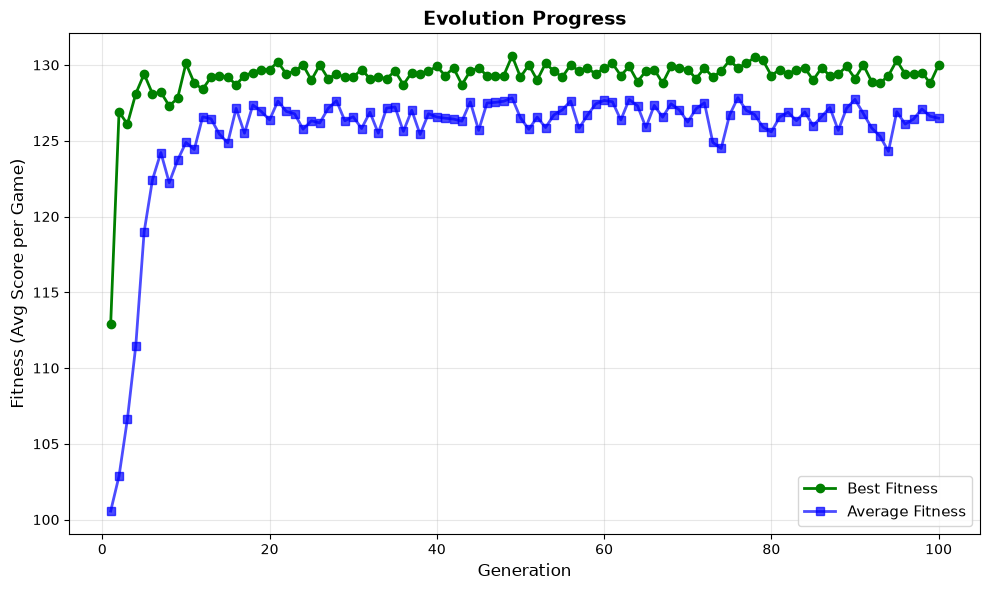


🎉 Your evolved agent's final genes:
   [1.0, 1.0, 1.0, 0.0, 0.08667143938633326, 0.5126953607411092]


In [7]:

# ============================================================================
# PART 4: RUN EVOLUTION! 
# ============================================================================

print("\n" + "="*70)
print("🚀 TIME TO EVOLVE YOUR AGENT!")
print("="*70)

# TODO: Experiment with these parameters to find the best agent!
my_evolved_agent = evolve(
    generations=100,       # Try: 50, 100, 250
    pop_size=30,         # Try: 15, 20, 30
    opponents=opponent_pool,
    mutation_rate=0.1,  # Try: 0.1, 0.15, 0.2
    elitism=2            # Keep top 2 agents each generation
)

print(f"\n🎉 Your evolved agent's final genes:")
print(f"   {my_evolved_agent.genes}")



In [8]:

# ============================================================================
# PART 5: TEST YOUR AGENT
# ============================================================================

print("\n" + "="*70)
print("⚔️  TESTING YOUR AGENT AGAINST HAND-CODED OPPONENTS")
print("="*70 + "\n")

wins = 0
losses = 0
ties = 0

for opponent in opponent_pool:
    game = Game(my_evolved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    
    if my_score > opp_score:
        result = "✅ WON"
        wins += 1
    elif my_score < opp_score:
        result = "❌ LOST"
        losses += 1
    else:
        result = "🤝 TIED"
        ties += 1
    
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\n📊 Record: {wins} wins, {losses} losses, {ties} ties")
win_rate = wins / len(opponent_pool) * 100
print(f"🎯 Win Rate: {win_rate:.1f}%")




⚔️  TESTING YOUR AGENT AGAINST HAND-CODED OPPONENTS

vs Gradual                  : 300 - 300  🤝 TIED
vs Generous Tit-for-Tat     : 300 - 300  🤝 TIED
vs Hard Majority            : 300 - 300  🤝 TIED
vs Grim Trigger             : 300 - 300  🤝 TIED
vs Pavlov                   : 300 - 300  🤝 TIED
vs Suspicious Tit-for-Tat   : 297 - 302  ❌ LOST
vs Always Undercut          :  97 - 112  ❌ LOST
vs Random (0.7)             : 275 - 280  ❌ LOST
vs Random (0.9)             : 291 - 291  🤝 TIED
vs Random (0.1)             : 143 - 158  ❌ LOST

📊 Record: 0 wins, 4 losses, 6 ties
🎯 Win Rate: 0.0%


# Unit 5 Part 2: Benchmark Analysis

**After running your initial evolution and benchmark tests, answer these questions.**

---

## Performance Summary

Fill in your benchmark results:

| Opponent | Result (W/L/T) | Your Score | Opp Score |
|----------|----------------|------------|-----------|
| Always Invest | Not Shown | - | - |
| Always Undercut | L | 97 | 112 |
| Tit-for-Tat | Not Shown | - | - |
| Grim Trigger | T | 300 | 300 |
| Pavlov | T | 300 | 300 |
| Tit-for-Two-Tats | Not Shown | - | - |
| Generous Tit-for-Tat | T | 300 | 300 |
| Adaptive | Not Shown | - | - |
| Random (0.7) | L | 275 | 280 |
| Random (0.3) | Not Shown | - | - |
| **Total** | _0_ W / _4_ L / _6_ T | | |

---

## Analysis Questions

### 1. What was your agent's worst loss (greatest point differential) and why?
(Write 3-5 sentences explaining what happened and why)
My agent's worst losses were against Always Undercut and Random (0.1), losing by 15 points in both matches. Against Always Undercut, my agent scored 97 points while the opponent scored 112. These results tell me that my agent struggled against these two strategies because of its poor response to their behaviors.

---

### 2. What pattern do you see in wins vs. losses?

(Which types of opponents does your agent beat/lose to? What do those agent types have in common?)
My agent did not win any matches, but it tied six opponents and lost to four. It tied against several strategies, including Grim Trigger, Pavlov, and Generous Tit-for-Tat, but struggled against Always Undercut and some of the random strategies. This tells me that my agent can hold its own against certain opponents but has trouble earning better results against more unpredictable strategies.

---

### 3. What would make an agent more competitive?

(What specific changes would you make? Why would these help? Think about how to outsmart the agents you're currently losing to)
I would improve my agent by making it better at recognizing patterns in its opponents behavior and adjusting its strategy in response. I would also experiment with different mutation rates and population sizes to see if the genetic algorithm could discover better combinations of genes. I would then test the improved agent against the opponents it lost to most often to see whether these changes actually improve its performance.

---

**Next:** Proceed to Part 3 to implement your improvements!

In [9]:

# ============================================================================
# PART 6: IMPROVE YOUR AGENT'S ACTION TAKING STRATEGY
# ============================================================================

class ImprovedEvolvableAgent(Agent):
    """
    IMPROVED agent with better gene encoding
    
    Students can modify:
    - Number of genes (currently 6, could add more)
    - What genes control
    - Decision logic (how genes map to actions)
    """
    
    def __init__(self, genes=None, name="Improved Agent"):
        if genes is None:

            genes = [random.random() for _ in range(6)]
        
        self.genes = genes
        super().__init__(name, f"Genes: [{', '.join([f'{g:.2f}' for g in genes])}]")
    
    def choose_action(self) -> bool:
        """
        IMPROVED decision logic - AGGRESSIVE VERSION
        More likely to retaliate, less exploitable
        """
        
        # First 3 rounds: use initial cooperation gene
        if self.round_num < 3:
            return random.random() < self.genes[0]
        
        # Calculate memory window
        memory_length = max(1, int(self.genes[4] * 10) + 1)
        recent_history = self.history[-memory_length:]
        cooperation_rate = sum(recent_history) / len(recent_history)
        
        # AGGRESSIVE STRATEGY: Higher threshold for cooperation
        
        # Only cooperate if opponent is VERY cooperative (>80%)
        if cooperation_rate > 0.8:
            return random.random() < self.genes[1]  # gene[1] should evolve HIGH
        
        # If somewhat cooperative (50-80%), be cautious
        elif cooperation_rate > 0.5:
            # Mix of cooperation and defection
            coop_prob = (
                self.genes[1] * self.genes[2]
                * (cooperation_rate - 0.5) * 2
            )
            return random.random() < coop_prob
        
        # If aggressive (<50%), retaliate hard
        else:
            # Mostly defect, with small chance to forgive
            if random.random() < self.genes[3] * self.genes[5] * 0.3:
                return INVEST
            else:
                return UNDERCUT
    
    def save_to_file(self, filename):
        """Save agent to JSON"""
        data = {
            'name': self.name,
            'genes': self.genes,
            'description': self.description
        }
        with open(filename, 'w') as f:
            json.dump(data, f, indent=2)
        print(f"✅ Agent saved to {filename}")


🔧 EVOLVING YOUR IMPROVED AGENT!

🧬 EVOLUTION STARTING (Improved Agent)
Population: 30 | Generations: 100 | Mutation: 0.1
Opponents: 10 | Elitism: 2

Gen   1/100: Best=108.10 | Avg=100.08 | Genes=['0.52', '0.48', '0.81', '0.07', '0.54', '0.76']
Gen   2/100: Best=114.00 | Avg=100.92 | Genes=['0.52', '0.48', '0.81', '0.07', '0.54', '0.63']
Gen   3/100: Best=114.00 | Avg=102.63 | Genes=['0.54', '0.84', '0.73', '0.07', '0.54', '0.63']
Gen   4/100: Best=114.00 | Avg=101.53 | Genes=['0.67', '0.94', '0.73', '0.88', '0.04', '0.63']
Gen   5/100: Best=114.00 | Avg=101.80 | Genes=['0.67', '0.94', '0.73', '0.88', '0.04', '0.63']
Gen   6/100: Best=118.80 | Avg=104.47 | Genes=['0.67', '0.94', '0.73', '0.88', '0.04', '0.63']
Gen   7/100: Best=118.80 | Avg=105.27 | Genes=['0.68', '0.94', '0.73', '0.88', '0.04', '0.63']
Gen   8/100: Best=120.20 | Avg=107.17 | Genes=['0.67', '0.94', '0.73', '0.53', '0.04', '0.63']
Gen   9/100: Best=128.50 | Avg=110.63 | Genes=['0.77', '1.00', '0.73', '0.53', '0.04', '0.

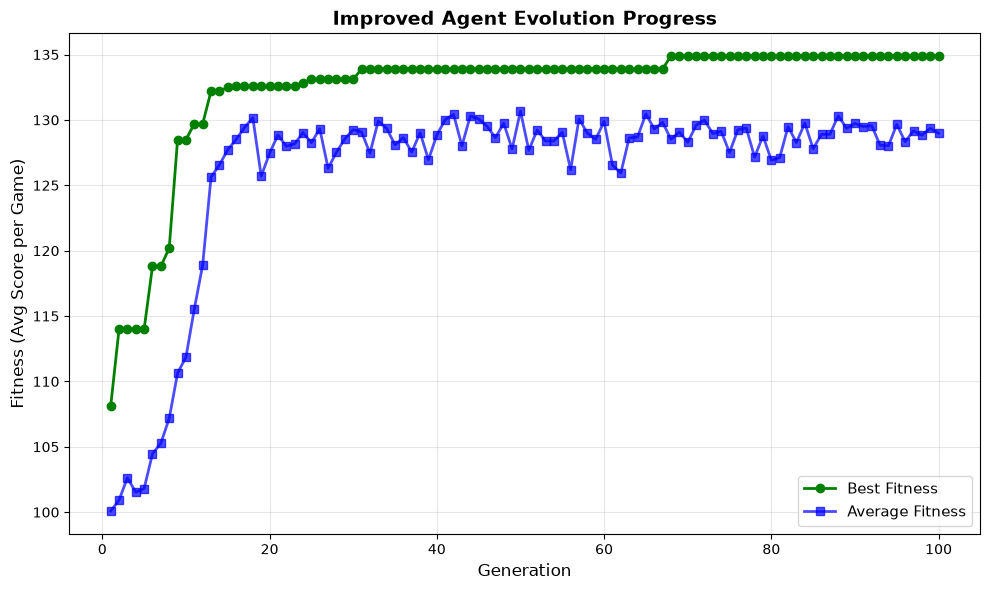


🎉 Your improved agent's final genes:
   [1.0, 1.0, 1.0, 0.0, 0.14415546620713768, 0.39808269999137247]


In [11]:
# ============================================================================
# PART 7: EVOLVE YOUR IMPROVED AGENT
# ============================================================================


print("\n" + "="*70)
print("🔧 EVOLVING YOUR IMPROVED AGENT!")
print("="*70)


def evolve_improved(generations=25, pop_size=20, opponents=None, mutation_rate=0.15, elitism=2):
    """
    Evolve using the ImprovedEvolvableAgent class
    (Same as evolve() but uses ImprovedEvolvableAgent instead of EvolvableAgent)
    """
    if opponents is None:
        opponents = opponent_pool
    
    print(f"\n🧬 EVOLUTION STARTING (Improved Agent)")
    print(f"{'='*70}")
    print(f"Population: {pop_size} | Generations: {generations} | Mutation: {mutation_rate}")
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print(f"{'='*70}\n")
    
    best_fitness_history = []
    avg_fitness_history = []
    
    # Initialize population with ImprovedEvolvableAgent
    population = [ImprovedEvolvableAgent(name=f"Agent_{i}") for i in range(pop_size)]
    
    best_overall_agent = None
    best_overall_fitness = -float('inf')
    
    for gen in range(generations):
        # Evaluate fitness
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(agent, opponents, num_rounds=50)
            fitnesses.append(fitness)
        
        # Track best
        best_fitness = max(fitnesses)
        avg_fitness = sum(fitnesses) / len(fitnesses)
        
        # Update best overall
        best_idx = fitnesses.index(best_fitness)
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            best_overall_agent = ImprovedEvolvableAgent(genes=population[best_idx].genes.copy())
        
        best_fitness_history.append(best_overall_fitness)
        avg_fitness_history.append(avg_fitness)
        
        print(f"Gen {gen+1:3d}/{generations}: "
              f"Best={best_overall_fitness:6.2f} | Avg={avg_fitness:6.2f} | "
              f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}")
        
        # Create next generation
        if gen < generations - 1:
            sorted_indices = sorted(range(len(fitnesses)), 
                                  key=lambda i: fitnesses[i], 
                                  reverse=True)
            
            # Elitism
            next_population = []
            for i in range(elitism):
                elite_genes = population[sorted_indices[i]].genes.copy()
                next_population.append(ImprovedEvolvableAgent(genes=elite_genes))
            
            # Selection
            selected = tournament_selection(population, fitnesses)
            
            # Crossover and mutation
            while len(next_population) < pop_size:
                parent1, parent2 = random.sample(selected, 2)
                child = crossover_and_mutate(parent1, parent2, mutation_rate)
                # Convert to ImprovedEvolvableAgent
                next_population.append(ImprovedEvolvableAgent(genes=child.genes))
            
            population = next_population
    
    print(f"\n{'='*70}")
    print(f"✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best fitness achieved: {best_overall_fitness:.2f}")
    print(f"{'='*70}\n")
    
    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, generations+1), best_fitness_history, 
             label='Best Fitness', linewidth=2, color='green', marker='o')
    plt.plot(range(1, generations+1), avg_fitness_history, 
             label='Average Fitness', linewidth=2, color='blue', marker='s', alpha=0.7)
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel('Fitness (Avg Score per Game)', fontsize=12)
    plt.title('Improved Agent Evolution Progress', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return best_overall_agent


# TODO: Experiment with these parameters to find the best improved agent!
my_improved_agent = evolve_improved(
    generations=100,      # Try: 20, 30, 50
    pop_size=30,         # Try: 15, 20, 30
    opponents=opponent_pool,
    mutation_rate=0.1,   # Try: 0.1, 0.15, 0.2
    elitism=2            # Keep top 2 agents each generation
)

print(f"\n🎉 Your improved agent's final genes:")
print(f"   {my_improved_agent.genes}")

In [12]:

# ============================================================================
# PART 8.1: Compare: Original vs Improved
# ============================================================================

print("\n" + "="*70)
print("📊 COMPARISON: Original vs Improved Agent")
print("="*70 + "\n")

print("ORIGINAL AGENT:")
wins_orig = 0
for opponent in opponent_pool:
    game = Game(my_evolved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    if my_score > opp_score:
        wins_orig += 1
        result = "✅ WON"
    elif my_score < opp_score:
        result = "❌ LOST"
    else:
        result = "🤝 TIED"
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\nOriginal Win Rate: {wins_orig / len(opponent_pool) * 100:.1f}%")

print("\n" + "-"*70 + "\n")

print("IMPROVED AGENT:")
wins_improved = 0
for opponent in opponent_pool:
    game = Game(my_improved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    if my_score > opp_score:
        wins_improved += 1
        result = "✅ WON"
    elif my_score < opp_score:
        result = "❌ LOST"
    else:
        result = "🤝 TIED"
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\nImproved Win Rate: {wins_improved / len(opponent_pool) * 100:.1f}%")

print("\n" + "="*70)
print(f"📈 IMPROVEMENT: +{wins_improved - wins_orig} wins")
print("="*70)


# ============================================================================
# GENERALIZATION TEST: Full Opponent Pool
# ============================================================================

print("\n" + "="*70)
print("🌍 GENERALIZATION TEST: Against ALL Possible Opponents")
print("="*70 + "\n")

print("Testing improved agent against the FULL opponent library:")
print("(including agents it was NOT trained on)\n")

wins_full = 0
losses_full = 0
ties_full = 0

for opponent in full_opponent_pool:
    game = Game(my_improved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    
    if my_score > opp_score:
        result = "✅ WON"
        wins_full += 1
    elif my_score < opp_score:
        result = "❌ LOST"
        losses_full += 1
    else:
        result = "🤝 TIED"
        ties_full += 1
    
    # Mark if this was a training opponent
    trained_on = "📚" if any(opponent.name == o.name for o in opponent_pool) else "🆕"
    print(f"{trained_on} vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\n📊 Results against ALL {len(full_opponent_pool)} opponents:")
print(f"   Wins: {wins_full} | Losses: {losses_full} | Ties: {ties_full}")
print(f"   Win Rate: {wins_full / len(full_opponent_pool) * 100:.1f}%")
print(f"\n💡 Legend: 📚 = Trained on this opponent | 🆕 = Never seen before")
print("="*70)


📊 COMPARISON: Original vs Improved Agent

ORIGINAL AGENT:
vs Gradual                  : 300 - 300  🤝 TIED
vs Generous Tit-for-Tat     : 300 - 300  🤝 TIED
vs Hard Majority            : 300 - 300  🤝 TIED
vs Grim Trigger             : 300 - 300  🤝 TIED
vs Pavlov                   : 300 - 300  🤝 TIED
vs Suspicious Tit-for-Tat   : 297 - 302  ❌ LOST
vs Always Undercut          :  97 - 112  ❌ LOST
vs Random (0.7)             : 261 - 266  ❌ LOST
vs Random (0.9)             : 290 - 290  🤝 TIED
vs Random (0.1)             : 118 - 123  ❌ LOST

Original Win Rate: 0.0%

----------------------------------------------------------------------

IMPROVED AGENT:
vs Gradual                  : 300 - 300  🤝 TIED
vs Generous Tit-for-Tat     : 300 - 300  🤝 TIED
vs Hard Majority            : 300 - 300  🤝 TIED
vs Grim Trigger             : 300 - 300  🤝 TIED
vs Pavlov                   : 300 - 300  🤝 TIED
vs Suspicious Tit-for-Tat   : 297 - 302  ❌ LOST
vs Always Undercut          :  97 - 112  ❌ LOST
vs Random (

In [14]:

# ============================================================================
# PART 8.2: Compete in your final tournament
# ============================================================================

print("\n" + "="*70)
print("🏆 FULL TOURNAMENT COMPARISON")
print("="*70 + "\n")

# Create tournament with original agent
print("Running tournament with ORIGINAL agent...")
original_tournament_agents = full_opponent_pool + [my_evolved_agent]
original_tournament = Tournament(original_tournament_agents, rounds_per_match=100, num_tournaments=1)
original_tournament.run_tournament()

# Create tournament with improved agent
print("\n" + "-"*70)
print("\nRunning tournament with IMPROVED agent...")
improved_tournament_agents = full_opponent_pool + [my_improved_agent]
improved_tournament = Tournament(improved_tournament_agents, rounds_per_match=100, num_tournaments=1)
improved_tournament.run_tournament()

# Compare rankings
print("\n" + "="*70)
print("📊 TOURNAMENT RESULTS COMPARISON")
print("="*70 + "\n")

original_rankings = original_tournament.get_rankings()
improved_rankings = improved_tournament.get_rankings()

# Find where each agent placed
original_rank = None
improved_rank = None
original_score = None
improved_score = None

for rank, (name, score) in enumerate(original_rankings, 1):
    if name == my_evolved_agent.name:
        original_rank = rank
        original_score = score

for rank, (name, score) in enumerate(improved_rankings, 1):
    if name == my_improved_agent.name:
        improved_rank = rank
        improved_score = score

print(f"ORIGINAL AGENT:")
print(f"  Rank: {original_rank} / {len(original_rankings)}")
print(f"  Total Score: {original_score:,}")
print()
print(f"IMPROVED AGENT:")
print(f"  Rank: {improved_rank} / {len(improved_rankings)}")
print(f"  Total Score: {improved_score:,}")
print()
print(f"IMPROVEMENT:")
print(f"  Rank Change: {original_rank - improved_rank} positions {'⬆️' if improved_rank < original_rank else '⬇️' if improved_rank > original_rank else '➡️'}")
print(f"  Score Change: +{improved_score - original_score:,} points ({(improved_score - original_score)/original_score*100:.1f}%)")
print("="*70)

# Show full leaderboard
print("\n🏆 IMPROVED AGENT TOURNAMENT LEADERBOARD:")
print("=" * 50)
for rank, (name, score) in enumerate(improved_rankings, 1):
    emoji = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉" if rank == 3 else "  "
    marker = " ⭐ YOUR AGENT" if name == my_improved_agent.name else ""
    print(f"{emoji} {rank:2d}. {name:25s}: {score:,} points{marker}")


🏆 FULL TOURNAMENT COMPARISON

Running tournament with ORIGINAL agent...
Running 1 tournament(s) with 19 agents...
Match 1/342: Always Invest vs Tit-for-Tat
Match 2/342: Always Invest vs Grim Trigger
Match 3/342: Always Invest vs Pavlov
Match 4/342: Always Invest vs Tit-for-Two-Tats
Match 5/342: Always Invest vs Generous Tit-for-Tat
Match 6/342: Always Invest vs Adaptive
Match 7/342: Always Invest vs Always Undercut
Match 8/342: Always Invest vs Suspicious Tit-for-Tat
Match 9/342: Always Invest vs Gradual
Match 10/342: Always Invest vs Prober
Match 11/342: Always Invest vs Hard Majority
Match 12/342: Always Invest vs Soft Majority
Match 13/342: Always Invest vs Random (0.9)
Match 14/342: Always Invest vs Random (0.7)
Match 15/342: Always Invest vs Random (0.5)
Match 16/342: Always Invest vs Random (0.3)
Match 17/342: Always Invest vs Random (0.1)
Match 18/342: Always Invest vs Evolved Agent
Match 19/342: Tit-for-Tat vs Always Invest
Match 20/342: Tit-for-Tat vs Grim Trigger
Match 21/34

In [15]:
# ============================================================================
# PART 9: Export Complete Agent as Python Module
# ============================================================================

import inspect
from datetime import datetime

def export_complete_agent(agent, student_name, generations=100, final_fitness=None):
    """
    Export agent as a complete, standalone Python module.
    This preserves BOTH genes AND decision logic so your strategy maintains
    its competitive edge in the tournament!
    
    Args:
        agent: Your evolved ImprovedEvolvableAgent
        student_name: Your name (will be used in class name, e.g., "JohnSmith")
        generations: Number of generations you evolved for
        final_fitness: Your agent's final fitness score (optional)
    
    Returns:
        filename of the exported Python file
    """
    
    # Clean up student name for valid Python class name (remove spaces, special chars)
    clean_name = ''.join(c for c in student_name if c.isalnum())
    
    # Get the actual decision logic code
    decision_code = inspect.getsource(agent.choose_action)
    
    # The source code already has proper indentation from the class,
    # so we don't need to add extra indentation
    
    # Get training opponent names if available
    try:
        opponent_names = [opp.name for opp in opponent_pool]
        opponent_info = f"Trained against: {', '.join(opponent_names[:5])}{'...' if len(opponent_names) > 5 else ''}"
    except:
        opponent_info = "Training opponents: [info not available]"
    
    # Build the complete Python module
    code = f'''#!/usr/bin/env python
"""
Tournament Agent: {agent.name}
Student: {student_name}
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

Evolution Details:
- Generations: {generations}
- Final Fitness: {final_fitness if final_fitness else 'N/A'}
- {opponent_info}

Strategy: {agent.description}
"""

from agents import Agent, INVEST, UNDERCUT
import random


class {clean_name}Agent(Agent):
    """
    {agent.name}
    
    {agent.description}
    
    Evolved Genes: {agent.genes}
    """
    
    def __init__(self):
        # These genes were evolved through {generations} generations
        self.genes = {agent.genes}
        
        # Required for tournament compatibility
        self.student_name = "{student_name}"
        
        super().__init__(
            name="{agent.name}",
            description="{agent.description}"
        )
    
{decision_code}


# Convenience function for tournament loading
def get_agent():
    """Return an instance of this agent for tournament use"""
    return {clean_name}Agent()


if __name__ == "__main__":
    # Test that the agent can be instantiated
    agent = get_agent()
    print(f"✅ Agent loaded successfully: {{agent.name}}")
    print(f"   Genes: {{agent.genes}}")
    print(f"   Description: {{agent.description}}")
'''
    
    # Save to file
    filename = f"{clean_name.lower()}_tournament_agent.py"
    with open(filename, 'w') as f:
        f.write(code)
    
    print("="*70)
    print("✅ COMPLETE TOURNAMENT AGENT EXPORTED!")
    print("="*70)
    print(f"📄 File: {filename}")
    print(f"🏷️  Class: {clean_name}Agent")
    print(f"🧬 Genes: {agent.genes}")
    print()
    print("📦 What's included:")
    print("   ✓ Your evolved gene values")
    print("   ✓ Your complete decision logic (choose_action method)")
    print("   ✓ All metadata and documentation")
    print()
    print("🎯 Next Steps:")
    print(f"   1. Download '{filename}' from Jupyter")
    print("   2. Submit this .py file for the Unit 6 tournament")
    print("   3. Your strategy will compete exactly as it evolved!")
    print()
    print("🧪 Test your export:")
    print(f"   from {filename[:-3]} import get_agent")
    print("   my_agent = get_agent()")
    print("="*70)
    
    return filename


# ============================================================================
# RUN THIS: Export your improved agent
# ============================================================================

print("\n" + "="*70)
print("💾 EXPORTING YOUR TOURNAMENT AGENT")
print("="*70 + "\n")

STUDENT_NAME = "Michael Caputo"  

my_improved_agent.name = "Hulk"
my_improved_agent.description = "destroy everything in sight"

print(f"Agent Name: {my_improved_agent.name}")
print(f"Description: {my_improved_agent.description}")
print(f"Genes: {[f'{g:.2f}' for g in my_improved_agent.genes]}\n")

# Export with all the context
exported_file = export_complete_agent(
    agent=my_improved_agent,
    student_name=STUDENT_NAME,
    generations=100,  # Update if you used different value
    final_fitness=134.20
)

print(f"\n✨ Your agent is ready for tournament competition!")
print(f"   Unlike JSON exports, this preserves your evolved strategy.\n")



💾 EXPORTING YOUR TOURNAMENT AGENT

Agent Name: Hulk
Description: destroy everything in sight
Genes: ['1.00', '1.00', '1.00', '0.00', '0.14', '0.40']

✅ COMPLETE TOURNAMENT AGENT EXPORTED!
📄 File: michaelcaputo_tournament_agent.py
🏷️  Class: MichaelCaputoAgent
🧬 Genes: [1.0, 1.0, 1.0, 0.0, 0.14415546620713768, 0.39808269999137247]

📦 What's included:
   ✓ Your evolved gene values
   ✓ Your complete decision logic (choose_action method)
   ✓ All metadata and documentation

🎯 Next Steps:
   1. Download 'michaelcaputo_tournament_agent.py' from Jupyter
   2. Submit this .py file for the Unit 6 tournament
   3. Your strategy will compete exactly as it evolved!

🧪 Test your export:
   from michaelcaputo_tournament_agent import get_agent
   my_agent = get_agent()

✨ Your agent is ready for tournament competition!
   Unlike JSON exports, this preserves your evolved strategy.



## Post-Evolution Reflection Questions

### 1. Generalization Analysis
- Compare your agent's performance on training opponents (📚) vs. unseen opponents (🆕)
- Did your agent generalize well or overfit to the training set?
- What does this suggest about evolving against a random sample vs. fixed opponents?
After the improvements, my agent performed better against random opponents in the training group, winning against Random (0.7), (0.9), and (0.1). In the full tournament test, it won 5 matches, lost 3, and tied 10. I think in general, my agent performed fairly well against different strategies, although it still struggled against opponents like Always Undercut, Suspicious Tit-for-Tat, and Prober.

### 2. Tournament Performance
- What was your agent's final tournament rank? _____ out of _____
- What was your agent's total score? _____
- Look at agents that ranked above and below you - what strategies do they use?
In the end, my agent's final tournament rank was 5 out of 19 and it's total score was 4,711. The agents ranked above mine included Gradual, Grim Trigger, and Hard Majority, which use different approaches to responding to an opponent's actions. My agent finished just ahead of Generous Tit-for-Tat. This shows that different strategies can produce similar results in the tournament.

### 3. Strategy Analysis
Look at your evolved genes: [1.0, 1.0, 1.0, 0.0, 0.1442, 0.3981]

- In plain English, what strategy did your agent evolve?
- Does it cooperate with cooperators? Does it punish defectors?
- Why do you think evolution discovered this particular strategy?
My agent evolved a strategy that strongly favors cooperation in some situations but can also respond differently depending on its opponent's behavior. The forgiveness gene only reached 0.0, meaning the agent's behavior was shaped more by its other decision rules than by that forgiveness setting. I think evolution discovered this combination because it performed well enough against the opponents used during training, although the results do not prove exactly why these gene values were selected.

### 4. Trade-offs
Every strategy has strengths and weaknesses.

- Which types of opponents does your agent beat?
- Which types beat your agent?
- If you could redesign your agent for Unit 6, what would you change?
My agent performed well against several random opponentsand it lost to Always Undercut, Suspicious Tit-for-Tat, and Prober, showing that it still has weaknesses against certain strategies. If I could redesigned it for Unit 6, I would improve how it recognizes and responds to different opponent behaviors and test it against a wider variety of strategies.

### 5. The Environment Matters
- You evolved against a random sample of 10 opponents
- The tournament included all 19 opponents
- Unit 6 will include 30+ student agents with unpredictable strategies
- How might your agent perform in that different environment?
My agent finished 5th out of 19 in the tournament, so it performed reasonably well against the strategies included in that test. With unit 6 including more student-created agents with unpredictable strategies, my agent might face behaviors it was not trained to handle. I would test it against more diverse opponents and experiment with its genes and decision rules to see whether it can perform consistently in a larger tournament.